<a href="https://colab.research.google.com/github/senanayakenithikas-ux/cm2604-churn-prediction/blob/main/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)

In [2]:
url = "https://raw.githubusercontent.com/senanayakenithikas-ux/cm2604-churn-prediction/main/data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(url)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Data inspection and cleaning

In [3]:
# Rows/columns, data types and non-null counts
print(df.shape)
df.info()

(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

In [4]:
# TotalCharges is text because some rows are blank " ". Convert: blanks -> NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())

# Who are these customers?
df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges"]]

Missing TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [5]:
# Tenure 0 = new customers not billed yet, so their true total is 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Missing now:", df["TotalCharges"].isna().sum())
print("Duplicate customers:", df["customerID"].duplicated().sum())

Missing now: 0
Duplicate customers: 0


df.info() showed TotalCharges stored as text (object), even though it holds money. Converting it with pd.to_numeric(errors="coerce") revealed 11 blank values. All 11 customers had tenure = 0, meaning they were new and had not received a bill yet, so I filled them with 0 rather than the mean (the mean would invent charges they never paid). No duplicate customers were found.

## 2. Target variable: churn distribution

       count  percent
Churn                
No      5174     73.5
Yes     1869     26.5


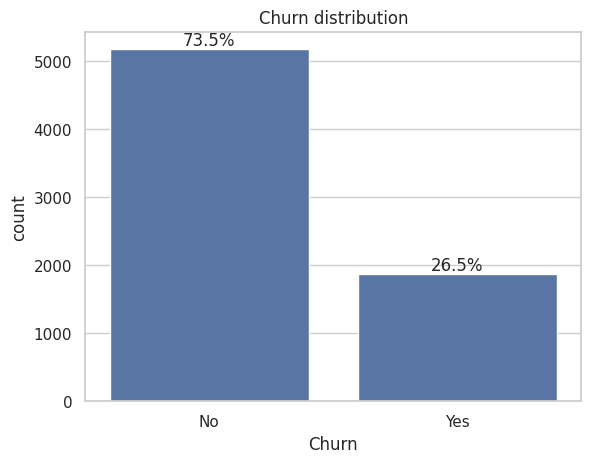

In [6]:
# Count and percentage of each class
counts = df["Churn"].value_counts()
pct = df["Churn"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": pct.round(1)}))

ax = sns.countplot(data=df, x="Churn", order=["No", "Yes"])
# Label each bar with its percentage
for bar, p in zip(ax.patches, pct[["No", "Yes"]]):
    ax.annotate(f"{p:.1f}%", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha="center", va="bottom")
plt.title("Churn distribution")
plt.savefig("figures/churn_distribution.png", dpi=150, bbox_inches="tight")  # save BEFORE show
plt.show()

The target variable is Churn (Yes/No). 73.5% of customers stayed and only 26.5% churned, so the dataset is imbalanced (about 3:1). A model that always predicts “No” would reach 73.5% accuracy without finding a single churner, so accuracy alone is misleading. I will evaluate models with recall, F1-score and ROC-AUC, and use a stratified train/test split to keep this ratio.